In [1]:
!pip install pyarrow

In [2]:
import pyarrow
import pandas as pd

train = pd.read_parquet("train.parquet")
test = pd.read_parquet("test.parquet")
train.head()


,lact_id,id,herd_id,calving_date,calving_year,parity,breed,age_at_calving_mo,calving_season,calving_month,...,herd_avg_protein_pct,herd_n_milking_cows,herd_avg_parity,herd_n_cows_total,spav,spav_reliability,has_ebv,target_milk_305_kg,target_fat_305_kg,target_protein_305_kg
0,5013136706,50131367,6437,2021-01-10,2021,6,EHF,88,winter,1,...,3.519362,353,2.872521,457,96,67.1,1,10419.20,414.371590,356.911330
1,5013136707,50131367,1347,2022-02-09,2022,7,EHF,101,winter,2,...,3.470788,45,3.800000,41,98,67.5,1,8624.30,367.634645,307.036165
2,5013137004,50131370,1984,2021-03-02,2021,4,EHF,90,spring,3,...,3.369819,76,2.407895,108,98,65.2,1,11372.10,412.823375,339.990775
3,5013138705,50131387,136,2021-05-14,2021,5,EHF,92,spring,5,...,3.389567,190,2.489474,232,98,65.8,1,10655.35,363.168615,337.022470
4,50090566909,500905669,19112,2021-06-05,2021,9,EK,230,summer,6,...,3.725933,16,2.125000,19,<NA>,NaN,0,3441.50,149.255325,127.166350


In [3]:
test.head()

,lact_id,id,herd_id,calving_date,calving_year,parity,breed,age_at_calving_mo,calving_season,calving_month,...,herd_avg_protein_pct,herd_n_milking_cows,herd_avg_parity,herd_n_cows_total,spav,spav_reliability,has_ebv,target_milk_305_kg,target_fat_305_kg,target_protein_305_kg
0,50391170514,503911705,7349,2025-03-23,2025,14,EHF,192,spring,3,...,3.328121,11,2.090909,17,74,53.7,1,6018.00,288.396075,213.881840
1,50401696413,504016964,241,2025-06-16,2025,13,EHF,183,summer,6,...,3.357766,516,2.858527,573,82,69.6,1,5436.00,174.115045,175.161165
2,50411584713,504115847,241,2025-09-06,2025,13,EHF,176,autumn,9,...,3.377407,506,2.772727,585,82,70.3,1,8246.95,328.892000,272.709095
3,50414922213,504149222,7352,2025-05-18,2025,13,EPK,169,spring,5,...,3.290263,14,4.500000,19,91,57.7,1,8554.10,389.882250,276.417330
4,50415996512,504159965,7352,2025-03-15,2025,12,EPK,165,spring,3,...,3.335301,9,4.444444,19,92,57.2,1,5708.25,236.771090,193.314545


In [4]:
sisendtunnused = ["calving_date", "calving_year", "parity", "breed", "age_at_calving_mo", "calving_season", "calving_month", "has_prev_lact", "prev_calving_interval", "prev_dry_days"]
#id väärtused ei aita meid
sihttunnused = ["target_milk_305_kg", "target_fat_305_kg", "target_protein_305_kg"]

In [5]:
num_sisendtunnused = ["age_at_calving_mo", "calving_year", "calving_month", "has_prev_lact", "prev_calving_interval", "prev_dry_days"]
#calving date pole vajalik sest calving month, season ja year juba on
cat_sisendtunnused = ["parity", "breed", "calving_season"]
corr_matrix = train[num_sisendtunnused + sihttunnused].corr()
corr_matrix

,age_at_calving_mo,calving_year,calving_month,has_prev_lact,prev_calving_interval,prev_dry_days,target_milk_305_kg,target_fat_305_kg,target_protein_305_kg
age_at_calving_mo,1.000000,-0.015821,0.025743,0.666864,0.218003,0.226871,0.121643,0.114190,0.073380
calving_year,-0.015821,1.000000,0.001762,-0.001354,-0.027544,-0.018582,0.166070,0.166435,0.181451
calving_month,0.025743,0.001762,1.000000,0.025027,-0.014437,-0.036664,0.056008,0.062515,0.069749
has_prev_lact,0.666864,-0.001354,0.025027,1.000000,NaN,NaN,0.337791,0.318822,0.318175
prev_calving_interval,0.218003,-0.027544,-0.014437,NaN,1.000000,0.336026,-0.077011,-0.066943,-0.120641
prev_dry_days,0.226871,-0.018582,-0.036664,NaN,0.336026,1.000000,-0.144435,-0.129687,-0.182266
target_milk_305_kg,0.121643,0.166070,0.056008,0.337791,-0.077011,-0.144435,1.000000,0.825269,0.958405
target_fat_305_kg,0.114190,0.166435,0.062515,0.318822,-0.066943,-0.129687,0.825269,1.000000,0.853738
target_protein_305_kg,0.073380,0.181451,0.069749,0.318175,-0.120641,-0.182266,0.958405,0.853738,1.000000


In [6]:
print(train.dtypes)

lact_id                           int64
id                                int64
herd_id                           int64
calving_date             datetime64[us]
calving_year                      int32
parity                            int64
breed                          category
age_at_calving_mo                 int64
calving_season                 category
calving_month                     int32
has_prev_lact                     int64
prev_calving_interval             Int64
prev_dry_days                     Int64
prev_milk_305                     Int64
prev_fat_305                    float64
prev_protein_305                float64
prev_peak_milk                  float64
herd_avg_milk_305               float64
herd_avg_fat_pct                float64
herd_avg_protein_pct            float64
herd_n_milking_cows               Int64
herd_avg_parity                 float64
herd_n_cows_total                 Int64
spav                              Int64
spav_reliability                float64


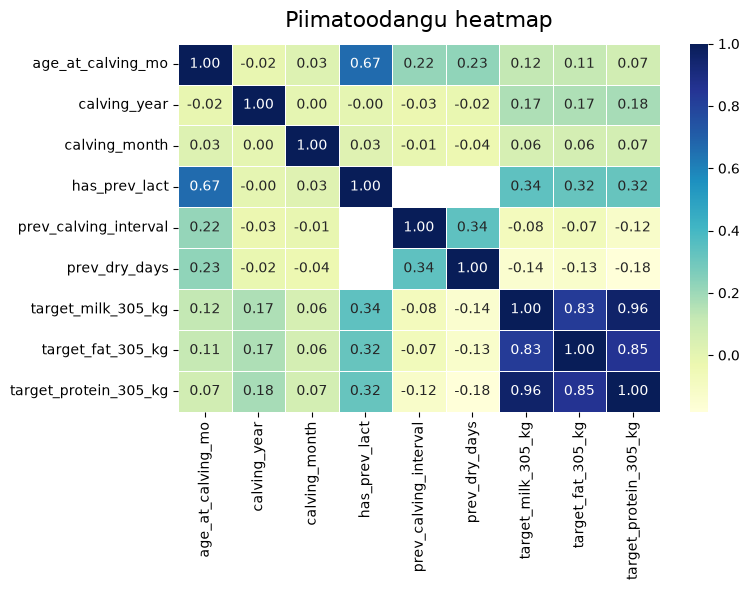

In [7]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,      
    fmt=".2f",         
    cmap="YlGnBu",     
    linewidths=0.5,     
    linecolor="white",   
    cbar=True            
)

# Add title
plt.title("Piimatoodangu heatmap", fontsize=16, pad=12)

# Display the plot
plt.tight_layout()
plt.show()

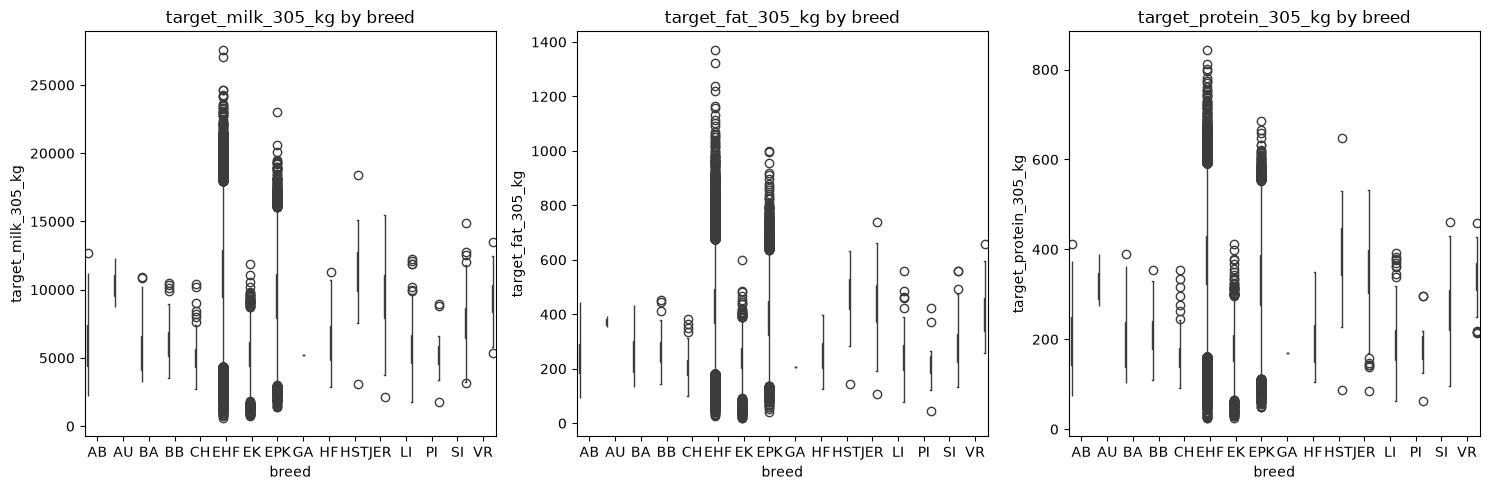

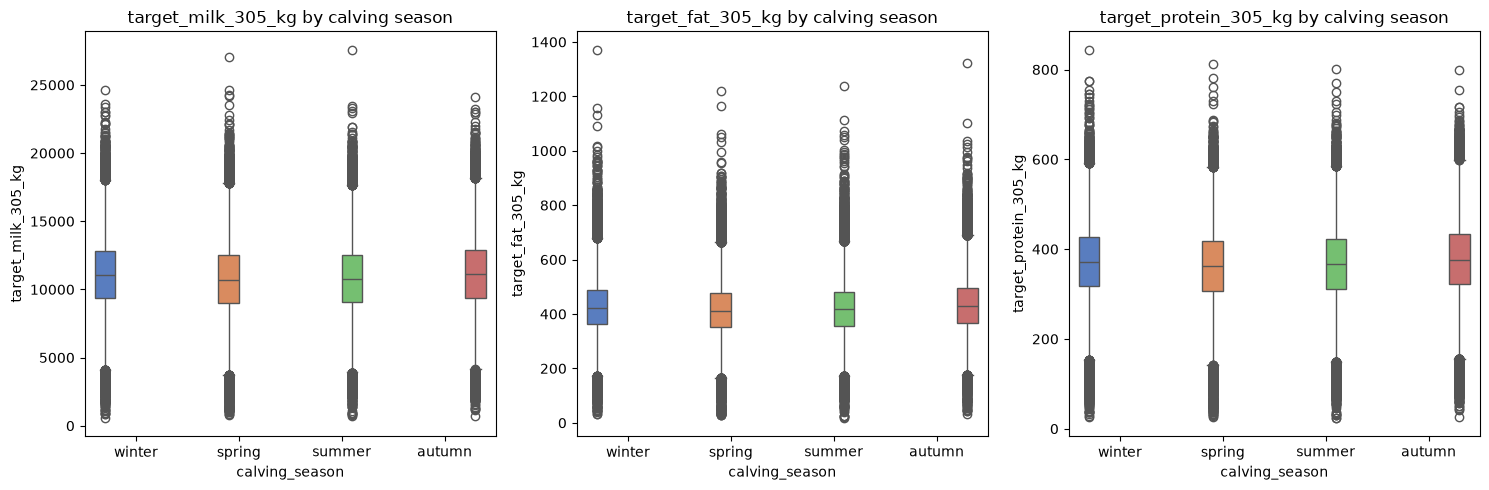

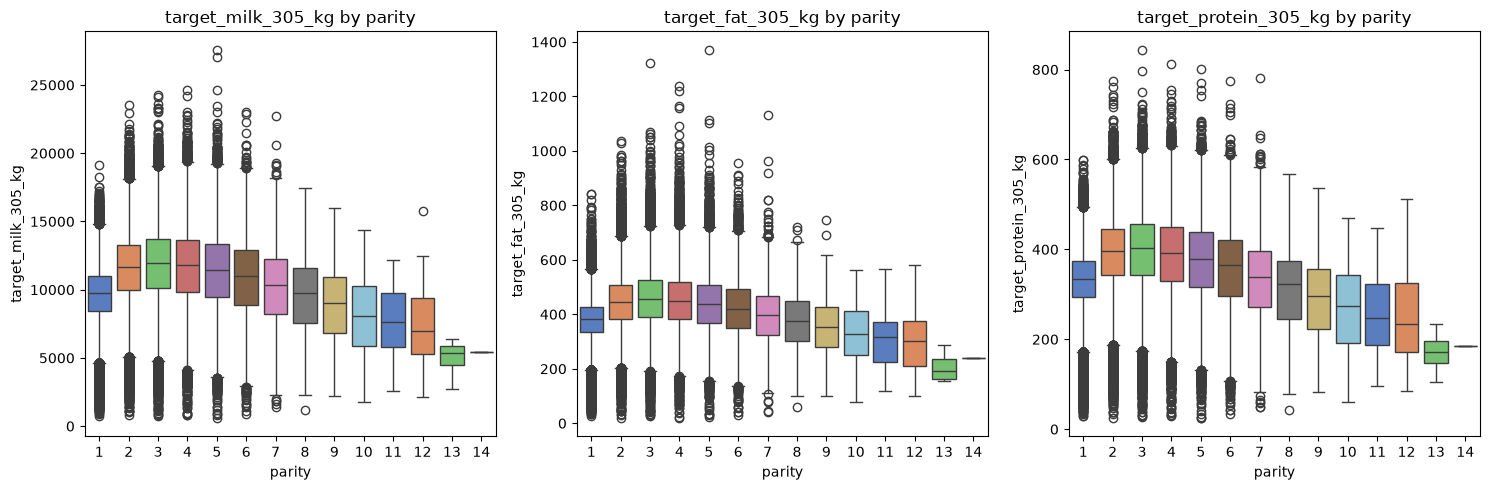

In [8]:
breed_keskmised = train.groupby("breed")[sihttunnused].mean()
calving_season_keskmised = train.groupby("calving_season")[sihttunnused].mean()
parity_keskmised = train.groupby("parity")[sihttunnused].mean()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, target in enumerate(sihttunnused):
    sns.boxplot(data=train, x="breed", y=target, ax=axes[i], palette="muted", hue="breed", legend=False)
    axes[i].set_title(f"{target} by breed")

plt.tight_layout()
plt.show()



fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, target in enumerate(sihttunnused):
    sns.boxplot(data=train, x="calving_season", y=target, ax=axes[i], palette="muted", hue="calving_season", legend=False)
    axes[i].set_title(f"{target} by calving season")

plt.tight_layout()
plt.show()



fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, target in enumerate(sihttunnused):
    sns.boxplot(data=train, x="parity", y=target, ax=axes[i], palette="muted", hue="parity", legend=False)
    axes[i].set_title(f"{target} by parity")

plt.tight_layout()
plt.show()

In [9]:
train["breed"].value_counts()

breed
EHF    278944
EPK     35156
EK       2335
SI        222
JER       208
LI        125
CH        116
AB        110
BB         95
VR         65
HF         51
HST        51
BA         45
PI         18
AU          4
GA          1
Name: count, dtype: int64

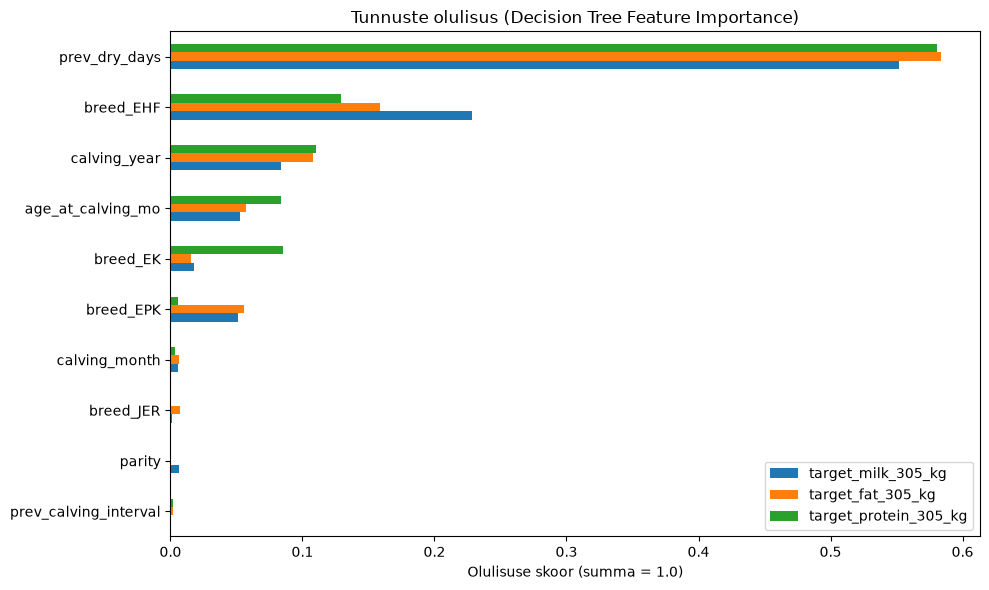

In [10]:
from sklearn.tree import DecisionTreeRegressor
features = num_sisendtunnused + cat_sisendtunnused
X = pd.get_dummies(train[features], drop_first=True).fillna(-1)
importances = pd.DataFrame(index=X.columns)
for target in sihttunnused:
    y = train[target]

    model = DecisionTreeRegressor(max_depth=6, random_state=42)
    model.fit(X, y)

    importances[target] = model.feature_importances_

importances["mean_importance"] = importances.mean(axis=1)
importances = importances.sort_values(by="mean_importance", ascending=True)
importances[sihttunnused].tail(10).plot(kind="barh", figsize=(10, 6))
plt.title("Tunnuste olulisus (Decision Tree Feature Importance)")
plt.xlabel("Olulisuse skoor (summa = 1.0)")
plt.tight_layout()
plt.show()

Piima, rasva- ja valgutoodangu korrelatsioonid jäävad vahemikku 0,83–0,96. See tähendab, et samad tegurid mõjutavad kõiki kolme toodangut väga sarnaselt

Kõige kõrgema piima-, rasva- ja valgutoodanguga on EHF (Eesti holstein) ja HST (keskmine piimatoodang ~11 000 kg), millele järgnevad EPK (Eesti punane) ja JER (džörsi). Teised tõud (nt EK, CH, PI) jäävad oluliselt madalamale (~5000 kg kanti). Lisaks selgus, et valdav enamus andmestikust koosneb EHF ja EPK tõugudest, samas kui mõnel tõul on vaid üksikud kirjed

Numbrilistest tunnustest oli kõige tugevam lineaarne seos tunnusega has_prev_lact (0,32–0,34), mis näitab, et korduvpoeginud lehmad annavad märgatavalt rohkem toodangut kui esmaspoegijad.

parity graafik: toodang on esimesel laktatsioonil madalam, saavutab haripunkti 3.–5. laktatsioonil ning hakkab vanematel lehmadel (alates 7. laktatsioonist) järk-järgult langema. Kuna tegu on kõvera seosega, ei sobi selle ennustamiseks lihtne lineaarne mudel, vaid puupõhised mudelid (nt Decision Tree, Random Forest)

calving_year on väike positiivne seos (0,17–0,18), viitab toodangu üldisele kasvutrendile aastate lõikes.

calving_month on lineaarne korrelatsioon peaaegu olematu (0,06–0,07), kuna kuud on tsüklilised

id, lact_id, herd_id ja täpne kuupäev calving_date on koodid/kuupäevad, millel puudub otsene numbriline ennustusjõud

Esmaspoegijatel (has_prev_lact == 0) puuduvad prev_calving_interval ja prev_dry_days, millega tuleb mudeli treenimisel arvestada.

Decision tree ütleb, et kõige tugevamad tunnused on:
1. prev_dry_days
2. breed_EHF
3. calving_year
4. age_at_calving_mo
5. breed_EK
6. breed_EPK